<center>

# **Predicción del rendimiento de corredores recreativos con Deep Learning**
### *Proyecto individual de Deep Learning*

<br><br>

**Miranda Urban Solano**  

Tecnológico de Monterrey, Campus Monterrey

**Materia:** Inteligencia artificial avanzada para la ciencia de datos

**Fecha de Entrega:** 12 de octubre de 2026

</center>
<br>

---

## Problema y pregunta
Para el desarrollo de este trabajo, el objetivo es predecir la **velocidad de carrera** de corredores recreativos a partir de sus características y hábitos de entrenamiento. Concretamente, la pregunta que guía el proyecto es:

> ¿Cuánto aportan las variables de entrenamiento (kilometraje semanal, intervalos, tempo runs) sobre las demográficas (edad, sexo, BMI) para predecir la velocidad en carrera con base en una red MLP que captura dichas interacciones no lineales?

El planteamiento de este problema es relevante porque permite entender qué factores accesibles para cualquier corredor, sin necesidad de pruebas de laboratorio, se asocian con el rendimiento. Por lo tanto, se presenta como una herramienta de gran utilidad práctica para optimizar el entrenamiento y evaluar el desempeño de forma masiva.

<br>

## Datos
A continuación se descibe a detalle la fuente de los datos que se utilizarán para el desarrollo de la solución:

- **Fuente:** Vickers & Vertosick (2016), *An empirical study of race times in recreational endurance runners*, BMC Sports Science, Medicine and Rehabilitation, 8:26.
- **Acceso:** https://pmc.ncbi.nlm.nih.gov/articles/PMC5000509/ (Additional file 2, `.xlsx`).
- **Licencia:** artículo bajo CC BY 4.0; los datos incluidos en el artículo y sus archivos adicionales se publican bajo la renuncia CC0, salvo indicación contraria.
- **Origen:** encuesta en línea (abril-junio de 2014) a corredores recreativos; datos autorreportados.
- **Estructura:** una fila por corredor (`id`), con columnas para cada distancia de carrera (`k5_*`, `k10_*`, `m5_*`, `m10_*`, `mh_*`, `mf_*`). Cada grupo tiene sufijos:
  - `_d`: distancia reportada
  - `_ti`: tiempo reportado
  - `_ti_adj`: tiempo ajustado
  - `_tr`: indicador de si terminó
  - `_di`: indicador de lesión/dificultad
- **Variable objetivo:** velocidad de carrera (derivada de distancia y tiempo).

<br>

## Alcance de este notebook
Este notebook tiene dos objetivos:

1. **Demostrar contacto con los datos:** carga correcta, número de ejemplos, estructura de las entradas, distribución del objetivo y riesgos observados.
2. **Sustentar la propuesta con una prueba preliminar:** entrenar de forma básica los modelos que propongo para verificar que el planteamiento es viable.
   - **Baselines:** media de velocidad por sexo y Ridge (regresión lineal regularizada).
   - **Modelo de Deep Learning:** MLP pequeña en PyTorch (2 capas ocultas, ReLU, dropout y weight decay).
   - **Evaluación:** una partición única por corredor, mismo preprocesamiento para todos los modelos y sin ajuste de hiperparámetros. Métricas: MAE y RMSE.

Estos resultados son **exploratorios**: no responden la pregunta de investigación. Sirven para comprobar que el pipeline funciona, tener un orden de magnitud del error y definir el experimento controlado de la entrega final (ablation de grupos de variables, validación cruzada por corredor y varias semillas). Como trabajo posterior se contempla añadir gradient boosting como referencia adicional y variantes de la MLP.

<br>

---


## Contenido
1. [Carga y estructura de los datos](#carga-estructura-datos)
2. [Evidencia de contacto con los datos](#evidencia-contacto-datos)
    - [Número de ejemplos y corredores](#num-ejemplos-corredores)
    - [Distribución del objetivo](#distribucion-objetivo)
    - [Distribución de las variables de entrada](#distribucion-variables-entrada)
    - [Datos faltantes y valores atípicos](#datos-faltantes-atipicos)
   - [Riesgos observados](#riesgos-observados)
3. [Baseline](#baseline)
4. [Familia de modelos](#familia-modelos)
5. [Primer experimento](#primer-experimento)
6. [Viabilidad](#viabilidad)
7. [Referencias](#referencias)
---

<a name="carga-estructura-datos"></a>
## 1. Carga y estructura de los datos
En esta sección se describe la fuente de los datos a detalle para la comprensión completa de los registros con los que se cuenta. Se explora su estructura, tipos de variables, qué representa cada columna relevante, la variable objetivo (target) y las features. Además, se documenta el formato de carga, el número total de filas y columnas, y cualquier transformación inicial necesaria.

El objetivo es tener una visión clara del dataset antes de cualquier análisis profundo.


In [1]:
# @title Importaciones y configuraciones
# Importanción de librerias relevantes
import os
import random
from pathlib import Path
from google.colab import drive

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch.utils.data import Dataset, DataLoader, random_split
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

# Declaración de seed para reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Declaraciones para visualizaciones
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
pd.set_option("display.max_columns", None)

# Uso de PyTorch
print("torch:", torch.__version__)
print("Dispositivo:", DEVICE)

torch: 2.11.0+cpu
Dispositivo: cpu


In [2]:
# Carga del archivo

drive.mount('/content/drive')
ruta_xlsx = '/content/drive/My Drive/Colab Notebooks/Deep Learning/Proyecto/Dataset/dataset_corredores.xlsx'

# Confirmación de carga y lectura
if not os.path.exists(ruta_xlsx):
    print(f"Error: El archivo no existe en la ruta especificada:\n   {ruta_xlsx}")
else:
    try:
        print("¡Archivo cargado y leído con éxito!")
    except Exception as e:
        print(f"Ocurrió un error al intentar leer el archivo de Excel: {e}")


Mounted at /content/drive
¡Archivo cargado y leído con éxito!


In [3]:
# @title Lectura del archivo
# Leer archivo
df = pd.read_excel(ruta_xlsx, sheet_name=0)

print(f"Dataset cargado: {df.shape[0]} filas × {df.shape[1]} columnas")
df.head()

Dataset cargado: 2303 filas × 50 columnas


,id,adjusted,age,bmi,cohort1,cohort2,cohort3,cohort4,endurancecat,endurancespeed,female,footwear,group,injury,k5_d,k5_di,k5_ti,k5_ti_adj,k5_tr,k10_d,k10_di,k10_ti,k10_ti_adj,k10_tr,m5_d,m5_di,m5_ti,m5_ti_adj,m5_tr,m10_d,m10_di,m10_ti,m10_ti_adj,m10_tr,mh_d,mh_di,mh_ti,mh_ti_adj,mh_tr,mf_d,mf_di,mf_ti,mf_ti_adj,mf_tr,max,sprint,tempo,typical,model1_time,model2_time
0,1,1,25.0,21.622116,NaN,NaN,NaN,NaN,1,2,1,2,2.0,1,NaN,NaN,NaN,NaN,NaN,10000.0,4.0,2798.0,2860.482422,2.0,NaN,NaN,NaN,NaN,NaN,16090.0,4.0,4612.0,4798.809082,2.0,21097.5,2.0,6320.0,6257.026367,2.0,NaN,NaN,NaN,NaN,NaN,47.0,1,0,30.0,NaN,NaN
1,2,1,41.0,23.905970,NaN,NaN,NaN,NaN,1,2,0,2,2.0,1,5000.0,3.0,1210.0,1210.000000,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21097.5,4.0,5510.0,5654.475586,1.0,NaN,NaN,NaN,NaN,NaN,28.0,1,1,23.0,NaN,NaN
2,3,1,25.0,21.640728,NaN,NaN,NaN,NaN,2,3,0,2,2.0,1,5000.0,3.0,994.0,994.000061,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21097.5,3.0,4520.0,4520.000000,2.0,NaN,NaN,NaN,NaN,NaN,70.0,1,1,50.0,NaN,NaN
3,4,1,35.0,23.592323,1.0,NaN,NaN,NaN,2,5,0,2,1.0,2,5000.0,3.0,1075.0,1075.000000,1.0,10000.0,5.0,2135.0,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42195.0,4.0,10295.0,10399.02832,1.0,60.0,1,1,50.0,NaN,NaN
4,5,1,34.0,22.706404,NaN,NaN,NaN,NaN,2,3,0,2,1.0,1,5000.0,3.0,1186.0,1186.000000,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16090.0,4.0,4120.0,4268.437012,3.0,21097.5,3.0,5475.0,5475.000000,2.0,NaN,NaN,NaN,NaN,NaN,15.0,0,0,8.0,NaN,NaN


In [4]:
# @title Estructura y tipos: parte 1
print("--- Información general del dataset ---")
df.info()

--- Información general del dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2303 entries, 0 to 2302
Data columns (total 50 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              2303 non-null   int64  
 1   adjusted        2303 non-null   int64  
 2   age             2303 non-null   float64
 3   bmi             2303 non-null   float64
 4   cohort1         929 non-null    float64
 5   cohort2         633 non-null    float64
 6   cohort3         493 non-null    float64
 7   cohort4         387 non-null    float64
 8   endurancecat    2303 non-null   int64  
 9   endurancespeed  2303 non-null   int64  
 10  female          2303 non-null   int64  
 11  footwear        2303 non-null   int64  
 12  group           2164 non-null   float64
 13  injury          2303 non-null   int64  
 14  k5_d            1387 non-null   float64
 15  k5_di           1387 non-null   float64
 16  k5_ti           1387 non-null   float6

In [5]:
# @title Estructura y tipos: parte 2
print("\n--- Estadísticas descriptivas ---")
display(df.describe(include="all").T)

print("\n--- Nombres de columnas ---")
for i, col in enumerate(df.columns):
    print(f"{i:2d}: {col}")


--- Estadísticas descriptivas ---


,count,mean,std,min,25%,50%,75%,max
id,2303.0,1154.437256,667.163997,1.000000,577.500000,1153.000000,1732.500000,2311.000000
adjusted,2303.0,0.939644,0.238197,0.000000,1.000000,1.000000,1.000000,1.000000
age,2303.0,36.421407,9.913292,16.000000,29.000000,35.000000,42.000000,74.000000
bmi,2303.0,23.745838,3.052466,15.428386,21.704651,23.374725,25.231911,47.184647
cohort1,929.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
cohort2,633.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
cohort3,493.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
cohort4,387.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
endurancecat,2303.0,1.833695,0.656222,1.000000,1.000000,2.000000,2.000000,4.000000
endurancespeed,2303.0,3.440729,1.768493,1.000000,2.000000,3.000000,4.000000,10.000000



--- Nombres de columnas ---
 0: id
 1: adjusted
 2: age
 3: bmi
 4: cohort1
 5: cohort2
 6: cohort3
 7: cohort4
 8: endurancecat
 9: endurancespeed
10: female
11: footwear
12: group
13: injury
14: k5_d
15: k5_di
16: k5_ti
17: k5_ti_adj
18: k5_tr
19: k10_d
20: k10_di
21: k10_ti
22: k10_ti_adj
23: k10_tr
24: m5_d
25: m5_di
26: m5_ti
27: m5_ti_adj
28: m5_tr
29: m10_d
30: m10_di
31: m10_ti
32: m10_ti_adj
33: m10_tr
34: mh_d
35: mh_di
36: mh_ti
37: mh_ti_adj
38: mh_tr
39: mf_d
40: mf_di
41: mf_ti
42: mf_ti_adj
43: mf_tr
44: max
45: sprint
46: tempo
47: typical
48: model1_time
49: model2_time


In [6]:
# @title Transformación a formato largo y variable objetivo

"""
Se pasa el dataset de formato ancho (una columna por distancia) a formato largo
(una fila por carrera). Se renombran las variables, se usa el tiempo ajustado por
dificultad (en segundos) y se calcula la velocidad en km/h como variable objetivo.
Las carreras sin tiempo ajustado se descartan de acuerdo con los críterios
declarados en el estudio para evitar subjetividad.
"""

MILE_KM = 1.60934

RACE_PREFIXES = {
    "k5":  ("5K",            5.0),
    "k10": ("10K",           10.0),
    "m5":  ("5mi",           5.0 * MILE_KM),
    "m10": ("10mi",          10.0 * MILE_KM),
    "mh":  ("Media maratón", 21.0975),
    "mf":  ("Maratón",       42.195),
}

# Variables por corredor (typical y max están en millas semanales)
RUNNER_COLS = ["id", "age", "bmi", "female", "endurancecat", "endurancespeed",
               "typical", "sprint", "tempo", "max", "injury", "footwear"]

# Sufijos por carrera -> nombre descriptivo
RACE_COLS = {
    "d":      "distancia_reportada_m",
    "ti":     "tiempo_s",
    "ti_adj": "tiempo_ajustado_s",
    "tr":     "forma_fisica",   # 1 = mejor forma de mi vida ... 4 = mal preparado
    "di":     "dificultad",     # 1 = muy difícil ... 5 = muy rápido
}


def build_long(df: pd.DataFrame) -> pd.DataFrame:
    """
    Una fila por carrera, con velocidad (km/h) calculada sobre el tiempo ajustado.
    """
    registros = []
    for prefix, (nombre, dist_km) in RACE_PREFIXES.items():
        src = {f"{prefix}_{s}": new for s, new in RACE_COLS.items()}
        if not all(c in df.columns for c in src):
            continue
        sub = df[RUNNER_COLS + list(src)].rename(columns=src)
        sub = sub.assign(distancia=nombre, distancia_km=dist_km)
        registros.append(sub)

    out = pd.concat(registros, ignore_index=True)
    out = out[out["tiempo_ajustado_s"].notna() & (out["tiempo_ajustado_s"] > 0)].copy()
    out["velocity_kmh"] = out["distancia_km"] / (out["tiempo_ajustado_s"] / 3600)
    return out


df_long = build_long(df)

print(f"Formato largo: {df_long.shape[0]} carreras, {df_long['id'].nunique()} corredores")
print("\nCarreras por distancia:")
print(df_long["distancia"].value_counts())
print("\n--- Distribución de velocidad (km/h) ---")
print(df_long["velocity_kmh"].describe())
print(f"Asimetría: {df_long['velocity_kmh'].skew():.3f}")
print(f"Curtosis:  {df_long['velocity_kmh'].kurtosis():.3f}")

Formato largo: 5153 carreras, 2164 corredores

Carreras por distancia:
distancia
Media maratón    1444
5K               1289
Maratón           929
10K               883
10mi              313
5mi               295
Name: count, dtype: int64

--- Distribución de velocidad (km/h) ---
count    5153.000000
mean       12.477590
std         2.594887
min         5.081157
25%        10.623382
50%        12.286824
75%        14.178318
max        22.126413
Name: velocity_kmh, dtype: float64
Asimetría: 0.315
Curtosis:  -0.113


/tmp/ipykernel_4175/677847404.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(data_by_dist, labels=orden)


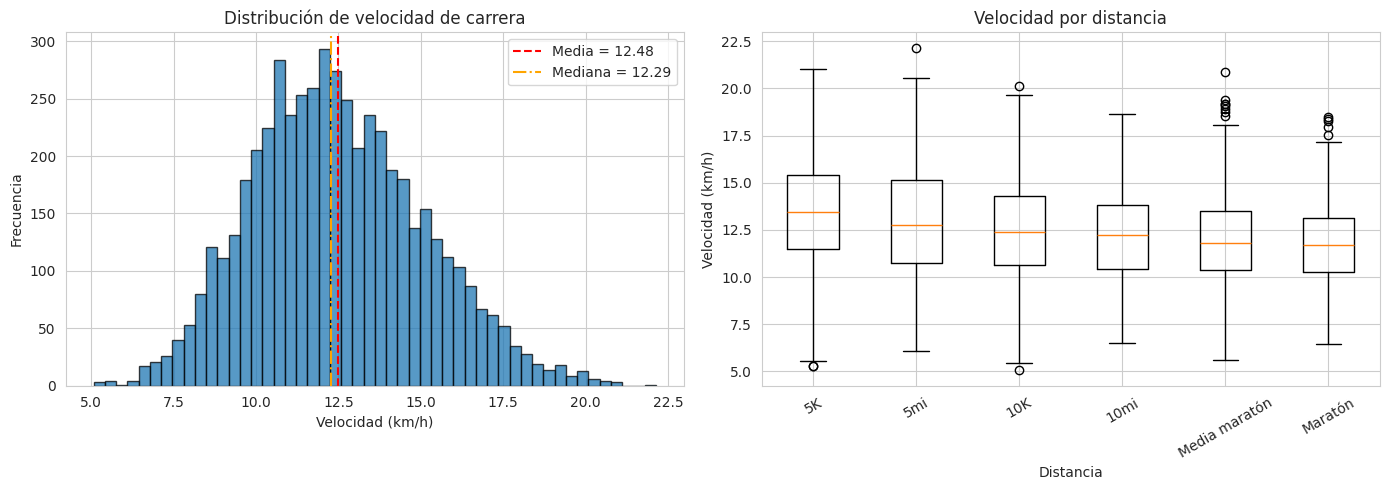

In [7]:
# @title Distribución del objetivo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_long["velocity_kmh"].dropna(), bins=50,
             edgecolor="black", alpha=0.75)
axes[0].axvline(df_long["velocity_kmh"].mean(), color="red", ls="--",
                label=f"Media = {df_long['velocity_kmh'].mean():.2f}")
axes[0].axvline(df_long["velocity_kmh"].median(), color="orange", ls="-.",
                label=f"Mediana = {df_long['velocity_kmh'].median():.2f}")
axes[0].set_xlabel("Velocidad (km/h)")
axes[0].set_ylabel("Frecuencia")
axes[0].set_title("Distribución de velocidad de carrera")
axes[0].legend()

# Velocidad por distancia
orden = ["5K", "5mi", "10K", "10mi", "Media maratón", "Maratón"]
orden = [d for d in orden if d in df_long["distancia"].unique()]
data_by_dist = [df_long[df_long["distancia"] == d]["velocity_kmh"].dropna() for d in orden]
axes[1].boxplot(data_by_dist, labels=orden)
axes[1].set_xlabel("Distancia")
axes[1].set_ylabel("Velocidad (km/h)")
axes[1].set_title("Velocidad por distancia")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

<a name="evidencia-contacto-datos"></a>
## 2. Evidencia de contacto con los datos

Esta sección presenta la evidencia obtenida directamente del código ejecutado sobre los datos: número de ejemplos y corredores, distribución del objetivo, distribución de las variables de entrada, datos faltantes, valores atípicos y riesgos observados. Todas las figuras y cifras provienen del presente notebook.

Ejemplos (carreras): 5153
Corredores únicos:   2164
Carreras por corredor (media): 2.38

--- Carreras por corredor ---
count    2164.000000
mean        2.381238
std         0.485803
min         2.000000
25%         2.000000
50%         2.000000
75%         3.000000
max         3.000000
dtype: float64


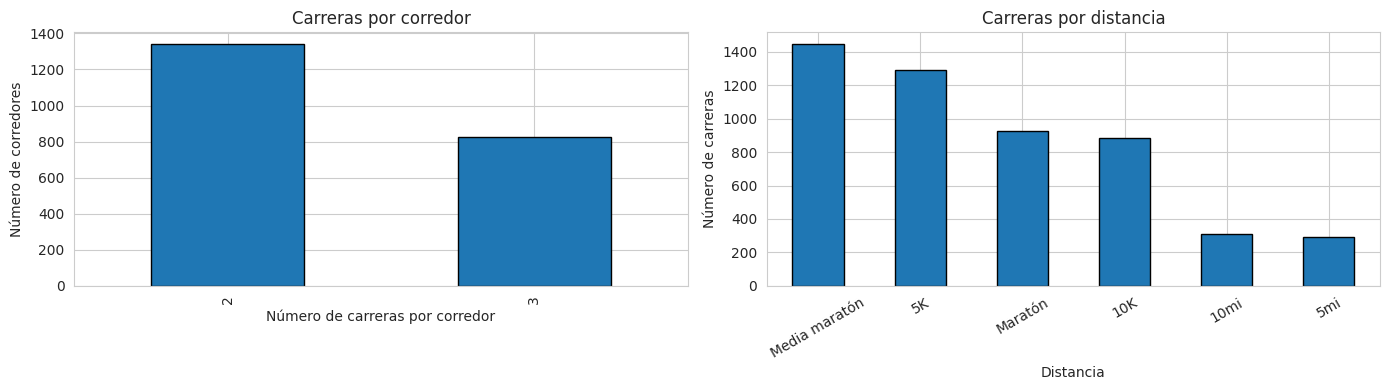

In [8]:
# @title Número de ejemplos y corredores
RUNNER_ID_COL = "id"

n_ejemplos = len(df_long)
n_corredores = df_long[RUNNER_ID_COL].nunique()

print(f"Ejemplos (carreras): {n_ejemplos}")
print(f"Corredores únicos:   {n_corredores}")
print(f"Carreras por corredor (media): {n_ejemplos / n_corredores:.2f}")

carreras_por_corredor = df_long.groupby(RUNNER_ID_COL).size()
print("\n--- Carreras por corredor ---")
print(carreras_por_corredor.describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

carreras_por_corredor.value_counts().sort_index().plot(
    kind="bar", ax=axes[0], edgecolor="black"
)
axes[0].set_xlabel("Número de carreras por corredor")
axes[0].set_ylabel("Número de corredores")
axes[0].set_title("Carreras por corredor")

df_long["distancia"].value_counts().plot(
    kind="bar", ax=axes[1], edgecolor="black"
)
axes[1].set_xlabel("Distancia")
axes[1].set_ylabel("Número de carreras")
axes[1].set_title("Carreras por distancia")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

--- Estadísticos del objetivo ---
Media:     12.478
Mediana:   12.287
Std:       2.595
Mínimo:    5.081
Máximo:    22.126
Asimetría: 0.315
Curtosis:  -0.113


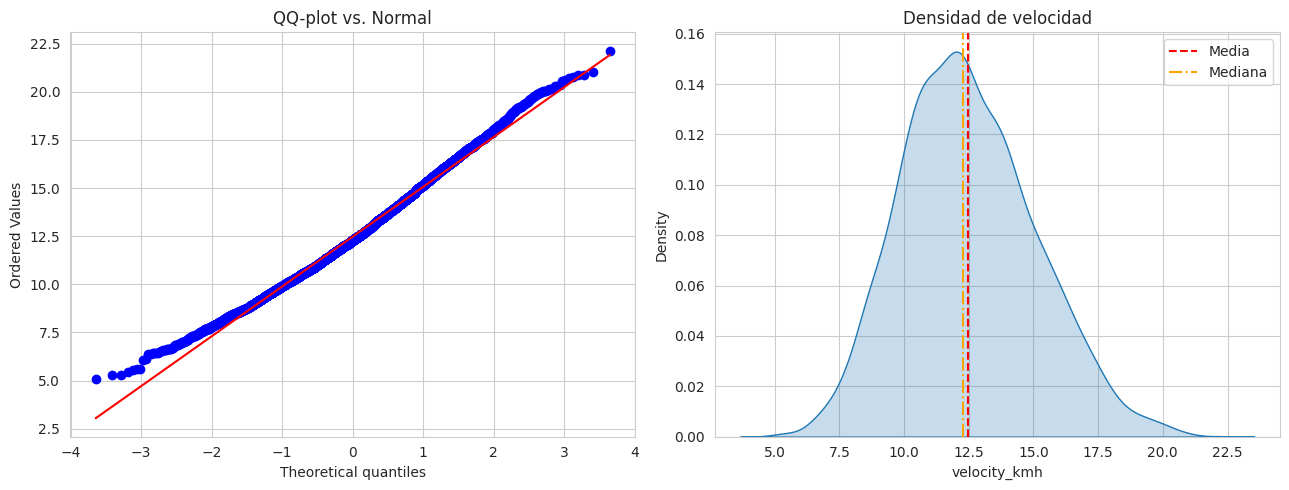

In [9]:
# @title Distribución del objetivo

from scipy import stats

target = df_long["velocity_kmh"].dropna()

print("--- Estadísticos del objetivo ---")
print(f"Media:     {target.mean():.3f}")
print(f"Mediana:   {target.median():.3f}")
print(f"Std:       {target.std():.3f}")
print(f"Mínimo:    {target.min():.3f}")
print(f"Máximo:    {target.max():.3f}")
print(f"Asimetría: {target.skew():.3f}")
print(f"Curtosis:  {target.kurtosis():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

stats.probplot(target, dist="norm", plot=axes[0])
axes[0].set_title("QQ-plot vs. Normal")

sns.kdeplot(target, ax=axes[1], fill=True)
axes[1].axvline(target.mean(), color="red", ls="--", label="Media")
axes[1].axvline(target.median(), color="orange", ls="-.", label="Mediana")
axes[1].set_title("Densidad de velocidad")
axes[1].legend()

plt.tight_layout()
plt.show()

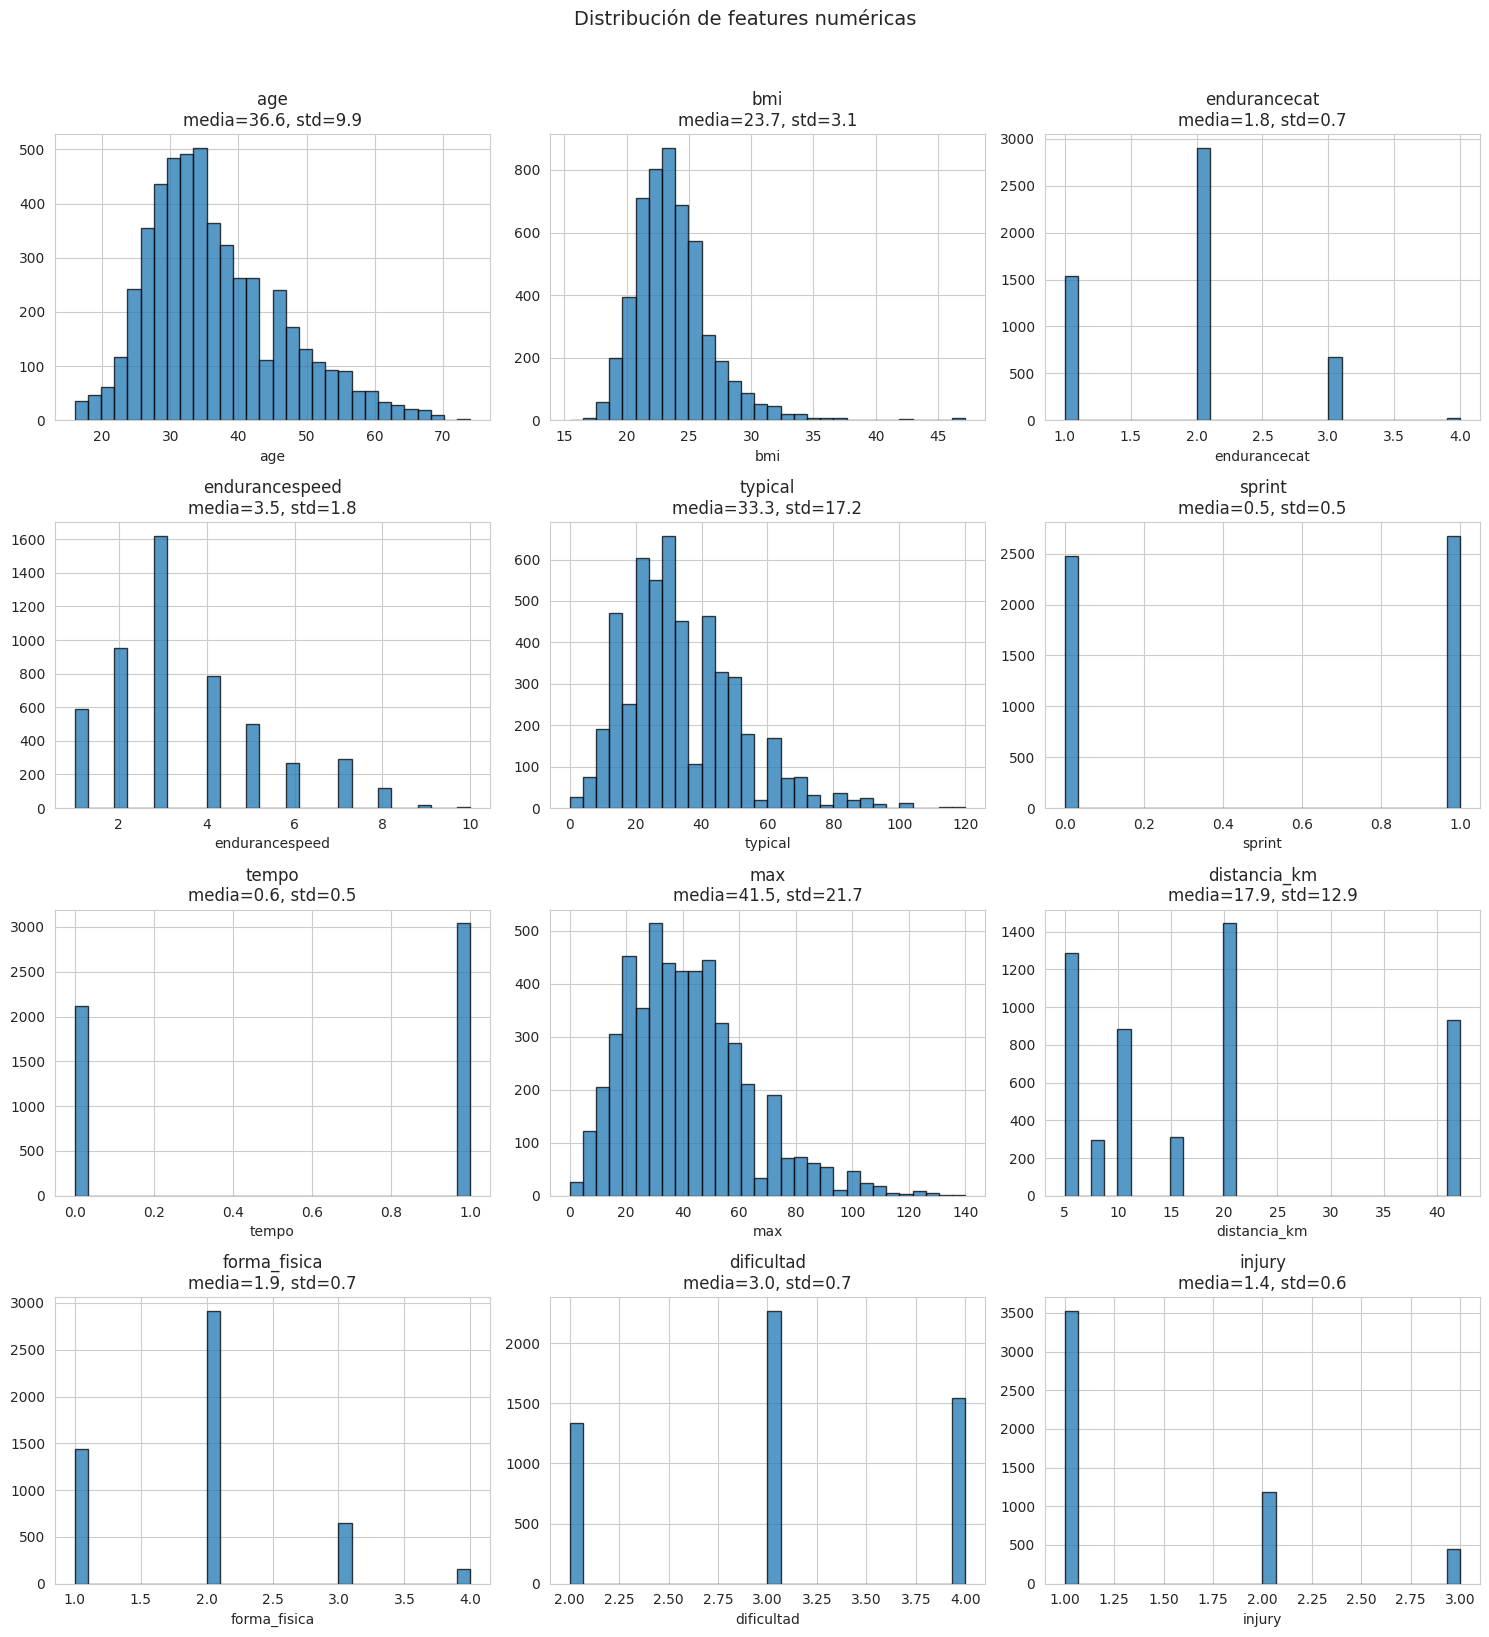

--- Correlación con velocidad ---
velocity_kmh      1.000000
typical           0.585837
max               0.554203
tempo             0.368965
sprint            0.328575
endurancespeed    0.219831
endurancecat      0.195310
dificultad        0.090723
injury           -0.070314
age              -0.168933
forma_fisica     -0.206220
distancia_km     -0.221445
bmi              -0.367324
Name: velocity_kmh, dtype: float64


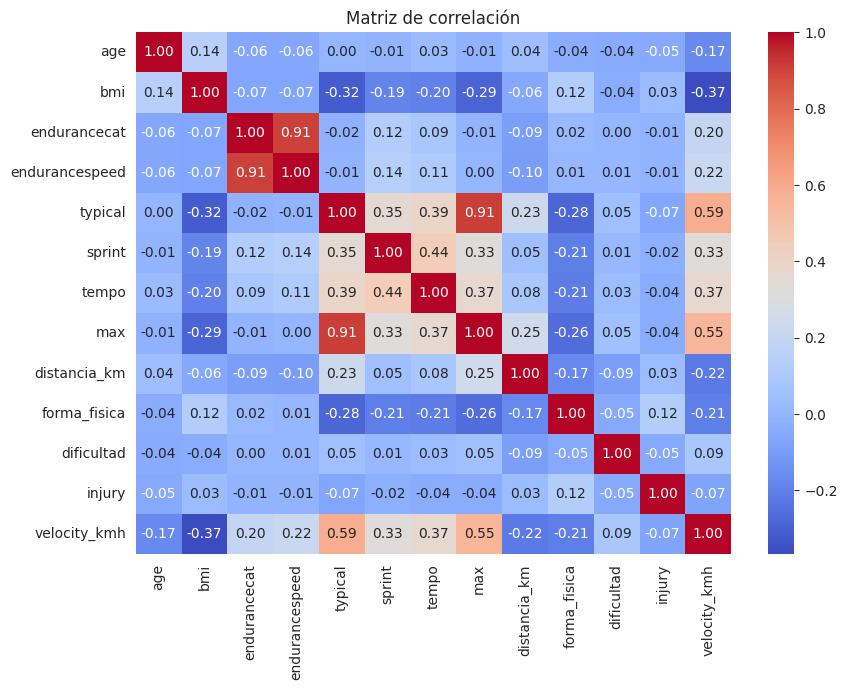

In [10]:
# @title Distribución de variables de entrada
numeric_features = [
    "age", "bmi", "endurancecat", "endurancespeed",
    "typical", "sprint", "tempo", "max", "distancia_km",
    "forma_fisica" ,"dificultad", "injury"
]
numeric_features = [c for c in numeric_features if c in df_long.columns]

n_cols = 3
n_rows = (len(numeric_features) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = np.array(axes).flatten()

for i, col in enumerate(numeric_features):
    axes[i].hist(df_long[col].dropna(), bins=30, edgecolor="black", alpha=0.75)
    axes[i].set_title(f"{col}\nmedia={df_long[col].mean():.1f}, std={df_long[col].std():.1f}")
    axes[i].set_xlabel(col)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Distribución de features numéricas", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

corr = df_long[numeric_features + ["velocity_kmh"]].corr()["velocity_kmh"].sort_values(ascending=False)
print("--- Correlación con velocidad ---")
print(corr)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df_long[numeric_features + ["velocity_kmh"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", ax=ax)
ax.set_title("Matriz de correlación")
plt.tight_layout()
plt.show()

In [11]:
# @title Variables categóricas
if "female" in df_long.columns:
    print("--- Distribución por sexo (female=1 → mujer) ---")
    print(df_long["female"].value_counts())
    print("\nProporción:")
    print(df_long["female"].value_counts(normalize=True).round(3))

--- Distribución por sexo (female=1 → mujer) ---
female
0    3153
1    2000
Name: count, dtype: int64

Proporción:
female
0    0.612
1    0.388
Name: proportion, dtype: float64


In [12]:
# @title Datos faltantes
missing = df_long.isnull().sum()
missing_pct = (missing / len(df_long) * 100).round(2)

missing_df = pd.DataFrame({
    "Faltantes": missing,
    "Porcentaje": missing_pct,
}).sort_values("Porcentaje", ascending=False)

print("--- Columnas con valores faltantes ---")
display(missing_df[missing_df["Faltantes"] > 0])


--- Columnas con valores faltantes ---


,Faltantes,Porcentaje


In [13]:
# @title Valores atípicos
def outliers_iqr(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (series < lower) | (series > upper)
    return mask.sum(), lower, upper

rows = []
for col in numeric_features + ["velocity_kmh"]:
    n_out, lo, hi = outliers_iqr(df_long[col].dropna())
    rows.append({
        "Variable": col,
        "N atípicos": n_out,
        "% atípicos": f"{n_out / len(df_long[col].dropna()) * 100:.2f}%",
        "Límite inferior": f"{lo:.2f}",
        "Límite superior": f"{hi:.2f}",
    })

outlier_df = pd.DataFrame(rows)
display(outlier_df)

,Variable,N atípicos,% atípicos,Límite inferior,Límite superior
0,age,49,0.95%,8.00,64.00
1,bmi,161,3.12%,16.42,30.48
2,endurancecat,28,0.54%,-0.50,3.50
3,endurancespeed,146,2.83%,-1.00,7.00
4,typical,71,1.38%,-17.50,82.50
5,sprint,0,0.00%,-1.50,2.50
6,tempo,0,0.00%,-1.50,2.50
7,max,74,1.44%,-20.00,100.00
8,distancia_km,0,0.00%,-19.15,45.24
9,forma_fisica,152,2.95%,-0.50,3.50


<a name="baseline"></a>
## 3. Baseline

Para tener un punto de comparación antes de aplicar cualquier modelo de Deep Learning, se definen dos baselines simples:

- **Media de velocidad por sexo:** predicción ingenua que asigna a cada carrera la media de velocidad observada en el conjunto de entrenamiento para ese sexo.
- **Ridge (regresión lineal regularizada):** modelo tradicional que usa todas las features con regularización L2. Sirve para medir cuánto de la señal es capturable con una relación lineal.

Ambos se evalúan con la misma partición por corredor, el mismo preprocesamiento y las mismas métricas (MAE y RMSE) que se usarán con la MLP, de modo que las comparaciones sean justas.

In [14]:
# @title Baselines: media por sexo y Ridge
from sklearn.linear_model import Ridge

TARGET = "velocity_kmh"

# Features agrupadas
FEATURE_GROUPS = {
    "demograficas":  ["age", "bmi", "female"],
    "entrenamiento": ["typical", "max", "sprint", "tempo", "endurancecat", "endurancespeed"],
    "carrera":       ["distancia_km", "forma_fisica", "dificultad"],
    "otras":         ["injury", "footwear"],
}
FEATURES = [c for cols in FEATURE_GROUPS.values() for c in cols]


def split_by_runner(d: pd.DataFrame, val_size=0.15, test_size=0.15, seed=SEED):
    """
    Partición por corredor para que ningún `id` aparezca en más de un conjunto.
    """
    groups = d["id"].to_numpy()
    outer = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    trainval, test = next(outer.split(d, groups=groups))
    inner = GroupShuffleSplit(n_splits=1, test_size=val_size / (1 - test_size), random_state=seed)
    tr, va = next(inner.split(d.iloc[trainval], groups=groups[trainval]))
    return trainval[tr], trainval[va], test


def evaluate(y_true, y_pred) -> dict:
    err = np.asarray(y_true) - np.asarray(y_pred)
    return {"MAE": np.abs(err).mean(), "RMSE": np.sqrt((err ** 2).mean())}


# Partición
assert not df_long[FEATURES + [TARGET]].isnull().any().any(), "Hay nulos en las features"
train_idx, val_idx, test_idx = split_by_runner(df_long)
train, val, test = (df_long.iloc[i] for i in (train_idx, val_idx, test_idx))

ids = [set(s["id"]) for s in (train, val, test)]
assert not (ids[0] & ids[1] or ids[0] & ids[2] or ids[1] & ids[2]), "Fuga: un corredor está en dos conjuntos"
print(f"Carreras: \n\t train: {len(train)} | val: {len(val)} | test (reservado): {len(test)}")
print(f"Corredores: \n\t train: {len(ids[0])} | val: {len(ids[1])} | test: {len(ids[2])}")

# Preprocesamiento
scaler = StandardScaler().fit(train[FEATURES])
X_train, X_val = scaler.transform(train[FEATURES]), scaler.transform(val[FEATURES])
y_train, y_val = train[TARGET].to_numpy(), val[TARGET].to_numpy()

# Baseline 1: media de velocidad por sexo
mean_by_sex = train.groupby("female")[TARGET].mean()
pred_sex = val["female"].map(mean_by_sex).fillna(y_train.mean()).to_numpy()

# Baseline 2: Ridge sobre todas las features
ridge = Ridge(alpha=1.0).fit(X_train, y_train)
pred_ridge = ridge.predict(X_val)

results = {
    "Media por sexo": evaluate(y_val, pred_sex),
    "Ridge":          evaluate(y_val, pred_ridge),
}
display(pd.DataFrame(results).T.round(3).rename_axis("Modelo (validación)"))

# Coeficientes estandarizados
coefs = pd.Series(ridge.coef_, index=FEATURES).sort_values(key=np.abs, ascending=False)
print("\n- Coeficientes de Ridge (features estandarizadas, km/h por 1 desv. est.)")
print(coefs.round(3))


Carreras: 
	 train: 3597 | val: 778 | test (reservado): 778
Corredores: 
	 train: 1514 | val: 325 | test: 325


,MAE,RMSE
Modelo (validación),,
Media por sexo,1.988,2.441
Ridge,1.140,1.454



- Coeficientes de Ridge (features estandarizadas, km/h por 1 desv. est.)
female           -0.941
typical           0.933
distancia_km     -0.894
bmi              -0.595
age              -0.476
endurancespeed    0.292
max               0.237
tempo             0.222
forma_fisica     -0.204
sprint            0.103
endurancecat     -0.069
footwear         -0.064
injury           -0.005
dificultad        0.005
dtype: float64


<a name="familia-modelos"></a>
## 4. Familia de modelos

Se propone una **MLP (multilayer perceptron)** porque las entradas son tabulares:
- una mezcla de variables numéricas (edad, BMI, kilometraje semanal, número de intervalos, etc.)
- categóricas codificadas (sexo, grupo de edad, etc.).

La MLP permite capturar interacciones no lineales entre volumen de entrenamiento, intensidad y demografía que una regresión Ridge no modela.

Como referencia adicional para la entrega final se contempla **gradient boosting**, que suele ser fuerte en datos tabulares y ayuda a distinguir si la ganancia proviene de la no linealidad o específicamente de una red neuronal.

In [26]:
# @title Familia de modelos: MLP

# Definiciones importantes para la construcción del modelo

import torch.nn as nn

class MLP(nn.Module):
    """MLP pequeña para regresión tabular.

    Arquitectura:
        entrada (n_features)
        - Linear(64) + ReLU + Dropout(0.2)
        - Linear(32) + ReLU + Dropout(0.2)
        - Linear(1)   # velocidad en km/h
    """
    def __init__(self, n_features, hidden=(64, 32), dropout=0.2):
        super().__init__()
        layers, prev = [], n_features
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)


def make_loader(X, y, batch_size=64, shuffle=True, seed=SEED):
    ds = torch.utils.data.TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.float32),
    )
    g = torch.Generator().manual_seed(seed)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, generator=g)


def predict(model, loader):
    """Predicciones en el orden del loader (usar solo con shuffle=False)."""
    model.eval()
    with torch.no_grad():
        return torch.cat([model(xb.to(DEVICE)).cpu() for xb, _ in loader]).numpy()


def rmse(y_true, y_pred):
    return np.sqrt(((y_pred - y_true) ** 2).mean())


def train_mlp(X_train, y_train, X_val, y_val, epochs=80, lr=1e-3, weight_decay=1e-4, seed=SEED):
    torch.manual_seed(seed)
    model = MLP(X_train.shape[1]).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.MSELoss()

    train_loader      = make_loader(X_train, y_train, shuffle=True,  seed=seed)  # para entrenar
    train_eval_loader = make_loader(X_train, y_train, shuffle=False)             # para medir RMSE de train
    val_loader        = make_loader(X_val,   y_val,   shuffle=False)

    history = {"train": [], "val": []}
    for ep in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()

        history["train"].append(rmse(y_train, predict(model, train_eval_loader)))
        history["val"].append(  rmse(y_val,   predict(model, val_loader)))
    return model, history

<a name="primer-experimento"></a>
## 5. Primer experimento

**Hipótesis:** una MLP pequeña captura interacciones no lineales entre variables de entrenamiento (kilometraje, intervalos, tempo runs) y demográficas (edad, sexo, BMI) que Ridge no logra, reduciendo el RMSE en validación.

- **Variable que se modifica:** familia de modelo (Ridge lineal vs. MLP con 2 capas ocultas, ReLU, dropout y weight decay).
- **Condiciones que se mantienen:** mismas features, misma partición por corredor, mismo preprocesamiento, sin ajuste de hiperparámetros.
- **Métrica principal:** RMSE en validación (MAE como secundaria).
- **Resultados que apoyarían la hipótesis:** RMSE de la MLP menor que el de Ridge.
- **Resultados que debilitarían la hipótesis:** RMSE de la MLP igual o peor que Ridge, lo que sugeriría que el problema es esencialmente lineal con estas features.

Este experimento es **preliminar**: no responde la pregunta de investigación, solo verifica que el pipeline es viable y da un orden de magnitud del error. El experimento controlado completo (ablation de grupos de variables, validación cruzada por corredor y varias semillas) se desarrollará en la entrega final.

,MAE,RMSE
Modelo (validación),,
Media por sexo,1.988,2.441
Ridge,1.140,1.454
MLP,1.165,1.503


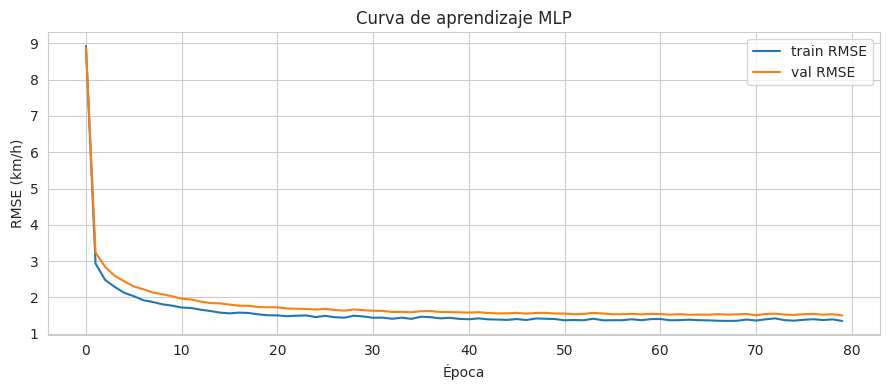

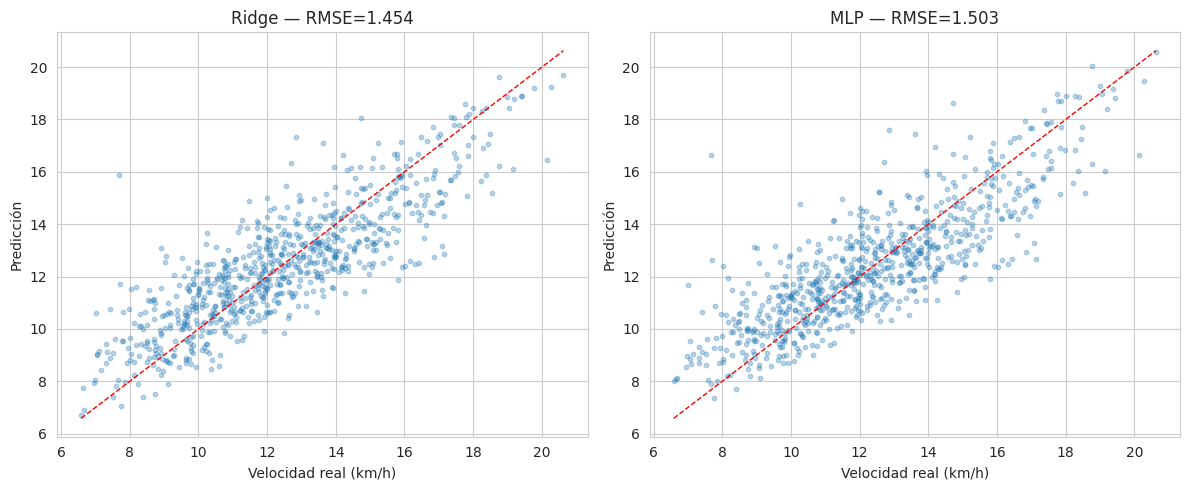

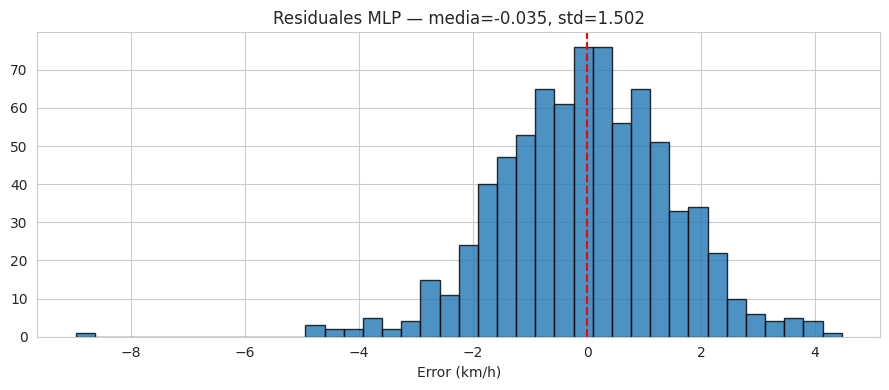

In [27]:
# @title Ridge vs. MLP

# 1. Entrenar MLP
mlp, hist = train_mlp(X_train, y_train, X_val, y_val)

# 2. Predicciones
mlp.eval()
with torch.no_grad():
    pred_mlp = mlp(torch.tensor(X_val, dtype=torch.float32).to(DEVICE)).cpu().numpy()

# 3. Añadir al comparativo
results["MLP"] = evaluate(y_val, pred_mlp)
display(pd.DataFrame(results).T.round(3).rename_axis("Modelo (validación)"))

# 4. Curva de aprendizaje
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(hist["train"], label="train RMSE")
ax.plot(hist["val"],   label="val RMSE")
ax.set_xlabel("Época"); ax.set_ylabel("RMSE (km/h)")
ax.set_title("Curva de aprendizaje MLP")
ax.legend(); plt.tight_layout(); plt.show()

# 5. Dispersión predicción vs. real (diagnóstico)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, pred) in zip(axes, [("Ridge", pred_ridge), ("MLP", pred_mlp)]):
    ax.scatter(y_val, pred, alpha=0.3, s=10)
    lims = [min(y_val.min(), pred.min()), max(y_val.max(), pred.max())]
    ax.plot(lims, lims, "r--", lw=1)
    ax.set_xlabel("Velocidad real (km/h)"); ax.set_ylabel("Predicción")
    ax.set_title(f"{name} — RMSE={results[name]['RMSE']:.3f}")
plt.tight_layout(); plt.show()

# 6. Residuales
residuals = y_val - pred_mlp
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(residuals, bins=40, edgecolor="black", alpha=0.8)
ax.axvline(0, color="red", ls="--")
ax.set_title(f"Residuales MLP — media={residuals.mean():.3f}, std={residuals.std():.3f}")
ax.set_xlabel("Error (km/h)"); plt.tight_layout(); plt.show()

<a name="viabilidad"></a>
## 6. Viabilidad

**Recursos:** el dataset es pequeño (aprox. 2 000 carreras, ~1 000 corredores), por lo que el entrenamiento puede realizarse en poco tiempo y sin infraestructura compleja.

**Tiempo estimado:** 2–3 semanas para la ablation completa con validación cruzada por corredor y varias semillas.

**Principal riesgo:** fuga de información por corredor si las particiones no se agrupan correctamente. Mitigación: filtrar por ID de corredor desde el inicio y verificar que ninguna carrera de un corredor aparezca en train y validación a la vez. Este riesgo está respaldado por la literatura sobre validación cruzada en datos estructurados: cuando existen dependencias (temporales, espaciales, jerárquicas o por grupo), la CV aleatoria subestima el error predictivo y puede favorecer el overfitting con predictores no causales, incluso en modelos que controlan correlaciones. Por ello se propone la adopción de *block CV* agrupada por corredor, más adecuada dado que el objetivo es predecir a nuevos datos o seleccionar predictores causales. Evidencia comparativa en 72 datasets tabulares (576 experimentos) respalda además que, en entornos complejos y ruidosos, los modelos no lineales como XGBoost o MLP rinden mejor que alternativas lineales, mientras que los lineales son más robustos en escenarios simples —de ahí que se mantenga Ridge como baseline y se contraste con la MLP.

**Alternativa de menor alcance:** si la ablation no muestra una ganancia clara de la MLP sobre Ridge, el proyecto se reorienta a un diagnóstico de qué variables aportan y bajo qué condiciones, sin cambiar de familia de modelo.

<a name="referencias"></a>
## 7. Referencias

> Roberts, D. R., Bahn, V., Ciuti, S., Boyce, M. S., Elith, J., Guillera-Arroita, G., Hauenstein, S., Lahoz-Monfort, J. J., Schroeder, B., Thuiller, W., Warton, D. I., Wintle, B. A., Hartig, F., & Dormann, C. F. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography*, *40*(8), 913–929. https://doi.org/10.1111/ecog.02881

> Stumpfe, S. F., & Shongwe, S. C. (2026). Comparative Analysis and Optimisation of Machine Learning Models for Regression and Classification on Structured Tabular Datasets. Mathematics, 14(3), 473. https://doi.org/10.3390/math14030473

> Vickers, A., & Vertosick, E. (2016). An empirical study of race times in recreational endurance runners. BMC sports science, medicine & rehabilitation, 8(1), 26. https://doi.org/10.1186/s13102-016-0052-y

<br>

### 7.1. Declaración de uso de inteligencia artificial

**Herramientas utilizadas:**

- DeepSeek se empleó exclusivamente como apoyo para mejorar la redacción de la documentación. Todas las sugerencias fueron revisadas, corregidas o descartadas por el alumno, quien mantuvo la responsabilidad final sobre el contenido, la estructura argumentativa y la versión final del texto.

- Claude se utilizó para asistir en la generación de código informático, siguiendo instrucciones explícitas proporcionadas por el alumno. Cada fragmento de código fue revisado, probado, corregido y validado por el alumno antes de su integración en el proyecto. Las decisiones de diseño, la interpretación de resultados y la depuración final permanecieron bajo control del alumno.

El uso de estas herramientas se realizó conforme a principios de transparencia y uso ético de IA. Ninguna salida fue incorporada sin verificación, y asumo la responsabilidad completa por la exactitud, originalidad y calidad del producto final.